# Lab 01

In [1]:
import os, re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_style("whitegrid")
print("numpy", np.__version__)
print("pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)

numpy 2.0.2
pandas 2.3.3
scikit-learn 1.6.1


## 1. Download and Load the Dataset

In [2]:
# Kaggle path (change this if running elsewhere)
base = "/kaggle/input/datasets/ashendulanjaya/test-new/sentiment+labelled+sentences/sentiment labelled sentences/"

cols = ["sentence", "label"]

amazon = pd.read_csv(base + "amazon_cells_labelled.txt", sep="\t", header=None, names=cols, quoting=3)
imdb   = pd.read_csv(base + "imdb_labelled.txt",         sep="\t", header=None, names=cols, quoting=3)
yelp   = pd.read_csv(base + "yelp_labelled.txt",         sep="\t", header=None, names=cols, quoting=3)

amazon["source"] = "amazon"
imdb["source"]   = "imdb"
yelp["source"]   = "yelp"

df = pd.concat([amazon, imdb, yelp], ignore_index=True)

print("Shape:", df.shape)
display(df.head())
print(df["label"].value_counts())

Shape: (3000, 3)


,sentence,label,source
0,So there is no way for me to plug it in here i...,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more...,0,amazon
4,The mic is great.,1,amazon


label
0    1500
1    1500
Name: count, dtype: int64


## 2. Basic Text Preprocessing
Steps applied to each sentence:
1. Convert to lowercase
2. Remove HTML tags and URLs
3. Remove digits, punctuation and special characters (apostrophes are kept so words like *don't* stay intact)
4. Remove extra whitespace

The result is stored in a new `clean_text` column so the original `sentence` is preserved for comparison.

In [3]:
def clean_text(text):
    text = str(text).lower()                         # lowercase
    text = re.sub(r"<.*?>", " ", text)               # HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)    # URLs
    text = re.sub(r"[^a-z\s']", " ", text)           # digits, punctuation, symbols
    text = re.sub(r"\s+", " ", text).strip()         # extra whitespace
    return text

df_clean = df.copy()
df_clean["clean_text"] = df_clean["sentence"].apply(clean_text)

# Drop empty rows and duplicate sentences
df_clean = df_clean[df_clean["clean_text"] != ""]
df_clean = df_clean.drop_duplicates(subset="clean_text").reset_index(drop=True)

print(f"Rows before: {len(df)}, after: {len(df_clean)}")

Rows before: 3000, after: 2971


### Original vs. preprocessed text

In [4]:
pd.set_option("display.max_colwidth", 80)
display(df_clean[["sentence", "clean_text"]].sample(10, random_state=7))

,sentence,clean_text
1530,I don't think there are any redeeming qualities in this remake.,i don't think there are any redeeming qualities in this remake
172,The iGo chargers and tips are really great.,the igo chargers and tips are really great
1619,"But it is entertaining, nonetheless.",but it is entertaining nonetheless
2414,I like Steiners because it's dark and it feels like a bar.,i like steiners because it's dark and it feels like a bar
691,Comfortable fit - you need your headset to be comfortable for at least an ho...,comfortable fit you need your headset to be comfortable for at least an hour...
694,"* Comes with a strong light that you can use to light up your camera shots, ...",comes with a strong light that you can use to light up your camera shots and...
1900,"Bad characters, bad story and bad acting.",bad characters bad story and bad acting
2742,The block was amazing.,the block was amazing
1032,"The film succeeds despite, or perhaps because of, an obviously meagre budget.",the film succeeds despite or perhaps because of an obviously meagre budget
1447,I was deeply impressed with the character he played.,i was deeply impressed with the character he played


## 3. Explore the Text Data

### 3.1 Class balance and data quality

Classes: [np.int64(0), np.int64(1)]
label
0    1486
1    1485
Name: count, dtype: int64

label     0    1
source          
amazon  494  489
imdb    497  497
yelp    495  499

Missing values:
 sentence      0
label         0
clean_text    0
dtype: int64

Sentence length (words):
count    2971.0
mean       11.9
std         7.9
min         1.0
25%         6.0
50%        10.0
75%        16.0
max        73.0
Name: n_words, dtype: float64


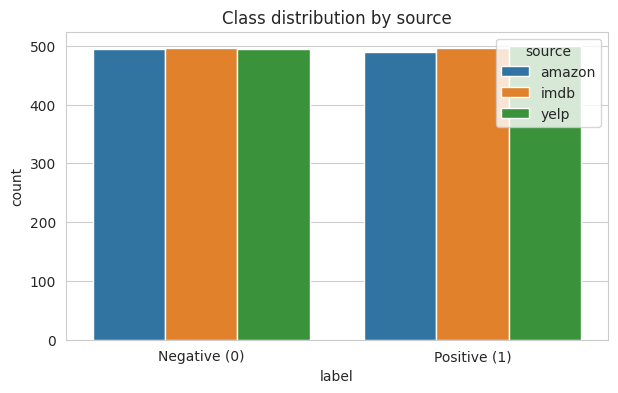

In [5]:
print("Classes:", sorted(df_clean["label"].unique()))
print(df_clean["label"].value_counts())
print()
print(pd.crosstab(df_clean["source"], df_clean["label"]))
print("\nMissing values:\n", df_clean[["sentence", "label", "clean_text"]].isnull().sum())

df_clean["n_words"] = df_clean["clean_text"].str.split().str.len()
print("\nSentence length (words):")
print(df_clean["n_words"].describe().round(2))

plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="label", hue="source")
plt.xticks([0, 1], ["Negative (0)", "Positive (1)"])
plt.title("Class distribution by source")
plt.show()

### 3.2 Positive and negative examples

In [6]:
print("POSITIVE examples:")
for s in df_clean[df_clean["label"] == 1]["sentence"].sample(5, random_state=1):
    print("  +", s)

print("\nNEGATIVE examples:")
for s in df_clean[df_clean["label"] == 0]["sentence"].sample(5, random_state=1):
    print("  -", s)

POSITIVE examples:
  + Exactly what I wanted.
  + Great bluetooth!.
  + The file browser offers all the options that one needs.Handsfree is great.
  + There is a brilliant twist ending.  
  + I have to say that this film was excellently produced and tops the ratings as a typical sci fi film!  

NEGATIVE examples:
  - Another note about this phone's appearance is that it really looks rather bland, especially in the all black model.
  - Improper description.... I had to return it.
  - But when I check voice mail at night, the keypad backlight turns off a few seconds into the first message, and then I'm lost.
  - Do not waste your time.  
  - The script looks as if only a rough draft was written and shooting began before a finished script was completed.  


### 3.3 Frequently occurring words
Common stopwords (the, is, and...) are filtered here so the chart shows informative words.

Overall top words: [('good', 231), ('great', 200), ('movie', 181), ('phone', 159), ('film', 159), ('food', 125), ('like', 124), ('just', 119), ("it's", 114), ('time', 112), ('place', 112), ('service', 108), ('bad', 103), ('really', 103), ('best', 78)]


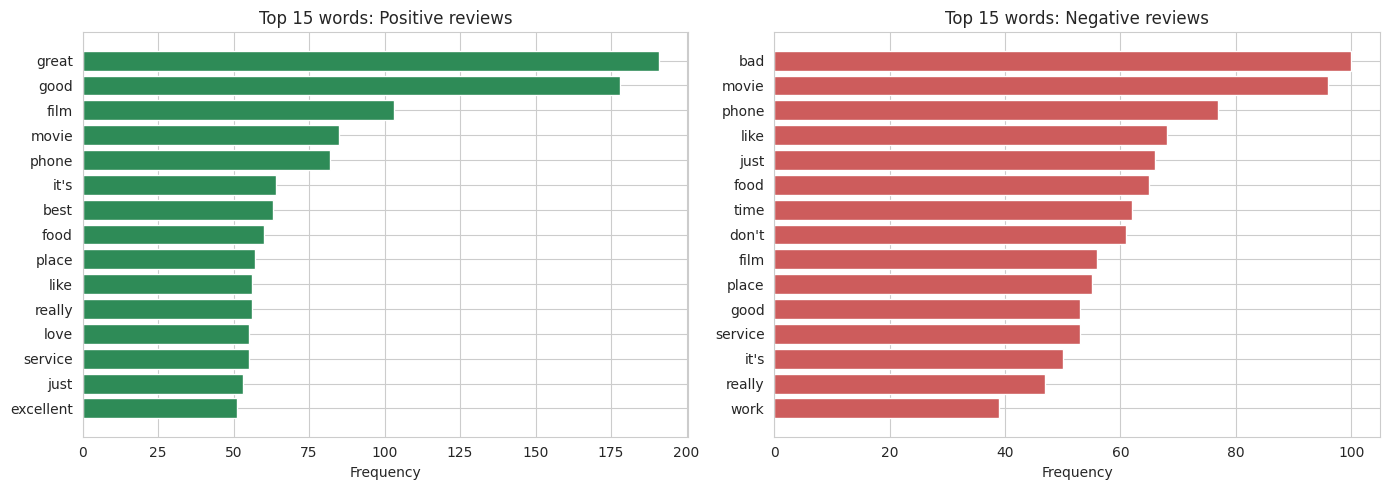

In [7]:
def top_words(texts, n=15):
    words = [w for t in texts for w in t.split()
             if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return Counter(words).most_common(n)

all_top = top_words(df_clean["clean_text"])
pos_top = top_words(df_clean[df_clean["label"] == 1]["clean_text"])
neg_top = top_words(df_clean[df_clean["label"] == 0]["clean_text"])

print("Overall top words:", all_top)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title, color in zip(axes, [pos_top, neg_top],
                                  ["Positive reviews", "Negative reviews"],
                                  ["seagreen", "indianred"]):
    words, counts = zip(*data)
    ax.barh(words[::-1], counts[::-1], color=color)
    ax.set_title(f"Top 15 words: {title}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### 3.4 Differences between positive and negative reviews

In [8]:
pos_words = set(w for w, _ in top_words(df_clean[df_clean["label"] == 1]["clean_text"], 30))
neg_words = set(w for w, _ in top_words(df_clean[df_clean["label"] == 0]["clean_text"], 30))

print("Only in top positive words:", sorted(pos_words - neg_words))
print("Only in top negative words:", sorted(neg_words - pos_words))
print("Common to both:", sorted(pos_words & neg_words))

print("\nAverage sentence length (words):")
print(df_clean.groupby("label")["n_words"].mean().round(2).rename({0: "Negative", 1: "Positive"}))

Only in top positive words: ['amazing', 'best', 'better', 'excellent', 'friendly', 'great', 'headset', 'love', 'nice', 'pretty', 'price', 'product', 'recommend', 'sound', 'wonderful', 'works']
Only in top negative words: ['acting', 'bad', 'did', "didn't", 'disappointed', "don't", "i'm", 'make', 'minutes', 'money', 'poor', 'terrible', 'waste', 'way', 'work', 'worst']
Common to both: ['film', 'food', 'good', "i've", "it's", 'just', 'like', 'movie', 'phone', 'place', 'quality', 'really', 'service', 'time']

Average sentence length (words):
label
Negative    11.92
Positive    11.87
Name: n_words, dtype: float64


## 4. Split the Dataset
An 80/20 train-test split is used.

In [9]:
X = df_clean["clean_text"]
y = df_clean["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", len(X_train))
print("Test size :", len(X_test))
print("\nTrain label ratio:\n", y_train.value_counts(normalize=True).round(3))

Train size: 2376
Test size : 595

Train label ratio:
 label
1    0.5
0    0.5
Name: proportion, dtype: float64


## 5. Bag of Words (BOW)
Each sentence is converted into word counts using `CountVectorizer`. The vocabulary is learned from the training data only.

Stopwords are kept because words like *not* matter (e.g. "not good").

In [10]:
bow = CountVectorizer()
X_train_bow = bow.fit_transform(X_train)
X_test_bow  = bow.transform(X_test)

print("Vocabulary size    :", len(bow.vocabulary_))
print("Train matrix shape :", X_train_bow.shape)
print("Test matrix shape  :", X_test_bow.shape)

# Peek at a few BOW features for one sentence
sample = X_train.iloc[0]
print("\nSample sentence:", sample)
vec = bow.transform([sample]).toarray()[0]
print({w: int(c) for w, c in zip(bow.get_feature_names_out(), vec) if c > 0})

Vocabulary size    : 4493
Train matrix shape : (2376, 4493)
Test matrix shape  : (595, 4493)

Sample sentence: nice solid keyboard
{'keyboard': 1, 'nice': 1, 'solid': 1}


## 6. Train Machine Learning Models
Two traditional classifiers are trained on the BOW features: **Logistic Regression** and a **Linear SVM**.

In [11]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_bow, y_train)

svm_model = LinearSVC()
svm_model.fit(X_train_bow, y_train)

print("Both models trained.")

Both models trained.


## 7. Evaluate the Models
Metrics: Accuracy, Precision, Recall and F1-score (positive class = 1).

In [12]:
models = {"Logistic Regression": lr_model, "Linear SVM": svm_model}
results = []

for name, model in models.items():
    pred = model.predict(X_test_bow)
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).round(3)
display(results_df)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.824,0.829,0.815,0.822
1,Linear SVM,0.807,0.807,0.805,0.806


=== Logistic Regression ===
              precision    recall  f1-score   support

    Negative       0.82      0.83      0.83       298
    Positive       0.83      0.81      0.82       297

    accuracy                           0.82       595
   macro avg       0.82      0.82      0.82       595
weighted avg       0.82      0.82      0.82       595

=== Linear SVM ===
              precision    recall  f1-score   support

    Negative       0.81      0.81      0.81       298
    Positive       0.81      0.80      0.81       297

    accuracy                           0.81       595
   macro avg       0.81      0.81      0.81       595
weighted avg       0.81      0.81      0.81       595



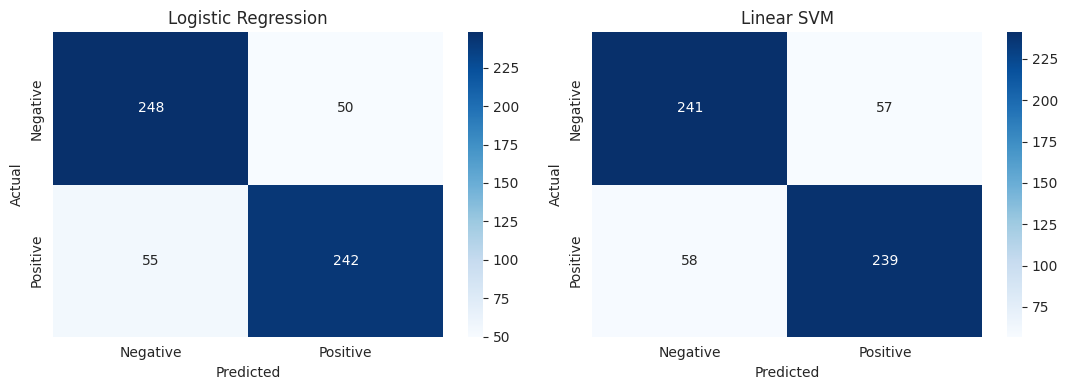

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test_bow)
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Negative", "Positive"]))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Negative", "Positive"],
                yticklabels=["Negative", "Positive"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [14]:
# Which words does Logistic Regression rely on most?
feature_names = np.array(bow.get_feature_names_out())
coefs = lr_model.coef_[0]
top_pos = feature_names[np.argsort(coefs)[-10:][::-1]]
top_neg = feature_names[np.argsort(coefs)[:10]]
print("Strongest POSITIVE words:", list(top_pos))
print("Strongest NEGATIVE words:", list(top_neg))

Strongest POSITIVE words: ['great', 'nice', 'excellent', 'amazing', 'awesome', 'delicious', 'good', 'love', 'perfect', 'happier']
Strongest NEGATIVE words: ['bad', 'worst', 'poor', 'terrible', 'not', 'awful', 'disappointment', 'wasn', 'doesn', 'then']


## 8. Test the Model with New Sentences

In [15]:
def predict_sentiment(sentence, model=lr_model):
    cleaned = clean_text(sentence)
    vec = bow.transform([cleaned])
    label = model.predict(vec)[0]
    return "Positive" if label == 1 else "Negative"

test_sentences = [
    "The food was amazing and the staff were very friendly",
    "This phone is terrible, the battery dies in an hour",
    "It was okay, nothing special",
    "I would not recommend this to anyone",
    "Absolutely loved this movie, the acting was brilliant",
    "Worst customer service I have ever experienced",
]

print(f"{'LogReg':9} | {'SVM':9} | Sentence")
print("-" * 70)
for s in test_sentences:
    print(f"{predict_sentiment(s, lr_model):9} | {predict_sentiment(s, svm_model):9} | {s}")

LogReg    | SVM       | Sentence
----------------------------------------------------------------------
Positive  | Positive  | The food was amazing and the staff were very friendly
Negative  | Negative  | This phone is terrible, the battery dies in an hour
Negative  | Negative  | It was okay, nothing special
Negative  | Negative  | I would not recommend this to anyone
Positive  | Positive  | Absolutely loved this movie, the acting was brilliant
Negative  | Negative  | Worst customer service I have ever experienced


In [16]:
# Try your own sentence
my_sentence = "The delivery was fast and the quality is great"
print(predict_sentiment(my_sentence), "|", my_sentence)

Positive | The delivery was fast and the quality is great


## 9. Conclusion
- The dataset is perfectly balanced (50% positive, 50% negative), so accuracy is a reliable metric.
- Text was cleaned into a `clean_text` column and converted to numeric features with Bag of Words.
- Logistic Regression and Linear SVM were trained and evaluated using accuracy, precision, recall and F1.
- **Limitations:** Bag of Words ignores word order and context, so sarcasm, negation and neutral sentences can be misclassified.
- **Possible improvements:** TF-IDF, n-grams (e.g. "not good"), hyperparameter tuning, or transformer-based models (covered in later labs).